## 지난 수업 복습

### REINFORCE와 Actor-Critic
1. REINFORCE
    - 에피소드 전체를 모은 뒤 Monte Carlo return 'G_t'를 계산하여 정책을 업데이트
    - 정책 경사의 기본 개념이 명료함. 분산 크고 에피소드 종료까지 기다려야 함

2. Actor-Critic 정책(Actor)과 가치 함수(Critic)를 동시에 학습하여, 더 안정적이고 효율적인 학습 가능
    - Actor는 정책 `π(a|s)`를 학습하고, Critice은 상태 가치 함수 `V(s)`를 학습
    - TD 목표 : `y_t = r_t + γ(1-d_t)V(s_{t+1})` 구함
    - Advantage 
        - 내가 선택한 행동이 평소 기대했던 것보다 얼마나 좋은지 나타냄
        - V(s): 현재 상태에서 앞으로 얼마나 많은 보상을 받을 것으로 기대되는지 나타냄
        - Advantage A(s, a): 현재 상태에서 행동이 평균적인 기대보다 얼마나 좋은지 나타냄
            - `A_t ≈ y_t − V(s_t)`
            - 값이 양수: 그 행동의 선택 확룰이 높아짐
            - 값이 음수: 그 행동의 선택 확률이 낮아짐
            ```
                평소 예상 점수는 70점이었는데, 실제로 90점을 받음
                    Advantage = 90 - 70 = +20
                평소 예상 점수는 70점이었는데, 실제로 50점을 받음
                    Advantage = 50 - 70 = -20
            ```
            - Advantage를 주면 무엇이 달라질까? 
                - 내가 움직여야 할 방향이 커져 학습을 할 때 더 빠르게 정책이 개선됨
                - 없어도 학습은 가능하지만, Advantage를 사용하면 정책 개선이 더 빠르게 이루어짐
    - Actor 손실 `L_actor = −log π(aₜ|sₜ) · stop_gradient(Aₜ)`
    - Critic 손실 `L_critic = (V(sₜ) − yₜ)²`
    - 손실을 구하는 이유:
        - Actor 손실: 정책을 개선하기 위해, Advantage가 양수일 때 행동 선택 확률을 높이고, 음수일 때 낮춤
        - Critic 손실: 상태 가치 함수가 TD 목표에 맞게 정확히 예측하도록 학습
    

___

# **1. A2C**
- A2C(Advantage Actor-Critic)는 정책(Actor)과 가치 함수(Critic)를 함께 학습하면서, Advantage를 이용해 정책의 방향을 정하는 Actor-Critic 계열 알고리즘이다.
- A2C는 n개의 환경이 일정한 길이 T만큼 경험을 수집한 뒤, 그 경험을 합쳐서 한 번에 신경망을 업데이트함

### **1-1. A2C의 배경**
- 단일 환경에서 연속으로 수집한 경험은 비슷한 장면이 반복
- 환경 여러개에서 서로 다른 상태를 경험하면 학습 배치가 다양해져 학습이 안정적이고 효율적으로 이루어짐
- 한 스텝만 보지 않고 n-step return을 사용해 조금 더 먼 미래의 보상까지 고려하여 정책을 업데이트함
- 동기시이므로 모든 환경이 모인 뒤 갱신해 업데이트 절차를 이해/재현하기 쉬움
    - 동기식으로 모든 환경이 모인 뒤 한 번에 업데이트함

학생 한명이 게임을 100번 하는게 아니라, 4명의 학생이 25번씩 게임을 해서 100번의 경험을 모으는것과 비슷 -> 이게 더 쉽지않은가? 이걸 나눠서 하고 합쳐서 사용방법에 대한 메뉴얼을 쓰는것이 동기식이고(차례 차례 이뤄지니까), 더 도움을 받지 않을까? 하는것 (점진적으로 좀 더 똑똑해지지 않을까?)

![A2C](./images/ref/05_01.png)

### **1-3. 수식들**

#### 1-3-1. 한 스텝 TD
- 1-step TD 목표값에서 현재 상태의 가치 V(sₜ)를 빼면 TD 오차구하는거
- 현재 보상과 다음 상태의 예상 가치를 더한 값으로, 한 스텝 뒤의 총 보상을 추정한 것
- 1 = 하나의 스텝

$
\boxed{G_t^{(1)}=r_t+\gamma V(s_{t+1})}
$


#### 1-3-2. n-step Return
- n개의 스텝에서 받은 보상과 마지막 상태의 예상 가치를 합한 값
- 1-step보다 더 먼 미래의 보상까지 고려함

$
\boxed{G_t^{(n)}=r_t+\gamma r_{t+1}+\cdots+\gamma^{n-1}r_{t+n-1}+\gamma^n V(s_{t+n})}
$


#### 1-3-3. Advantage
- n-step Return에서 현재 상태의 예상 가치를 뺀 값
- 양수면 예상보다 좋은 행동, 음수면 예상보다 나쁜 행동

$
\boxed{A_t=G_t^{(n)}-V(s_t)}
$


#### 1-3-4. 전체 손실 
- Actor Loss: Advantage를 이용해 행동 선택 확률을 학습
- Critic Loss: 예측 가치와 목표값의 차이를 줄이도록 학습
- Entropy: 특정 행동에만 치우치지 않도록 탐색을 장려

$
\boxed{L=-\mathbb E[\log\pi(a_t|s_t)\,\mathrm{stopgrad}(A_t)]+c_v\mathbb E[(V(s_t)-G_t^{(n)})^2]-c_e\mathbb E[H(\pi(\cdot|s_t))]}
$

> n-step의 n은 신경망의 층 수가 아니라, 앞으로 관찰한 보상의 스텝수임!!

### **1-4. 예시 문제 (Advantage 계산)**

#### 1-4-1. 문제 설정
```
r_0 = 1     : 첫 번째 행동 후 받은 보상
r_1 = 1     : 두 번째 행동 후 받은 보상
r_2 = 1     : 세 번째 행동 후 받은 보상
γ = 0.9     : 미래 보상에 적용하는 할인율
V(s_3) = 5  : 세번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
V(s_0) = 4  : 첫 번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
```

#### 1-4-2. 문제 풀이
1. AI가 3번의 행동으로 실제 받은 보상의 합계는 얼마일까?
    - r_0 + r_1 + r_2 = 1 + 1 + 1 = 3
2. 미래 보상에 할인율을 적용해 계산한 3-step Return은 얼마일까?
    - G_0 = r_0 + γ * r_1 + γ^2 * r_2 + γ^3 * V(s_3)
    - = 1 + 0.9 * 1 + 0.9^2 * 1 + 0.9^3 * 5
    - = 1 + 0.9 + 0.81 + 3.645
    - = 6.355
    - 이 6.355는 실제 받은 보상(3점)과 앞으로 받을 것으로 예상되는 보상(3번 행동한 이후 매라 예상 가치)을 모두 고려한 값이다.
3. 처음 예상했던 가치와 비교한 Advantage는 얼마일까?
    - Advantage = 처음 예상했던 가치와 새롭게 계산한 목표 가치의 차이임
        - Critic은 현재 상태의 가치를 4점이라 예상함
        - 3번 행동한 경험과 미래 예상 가치를 이용해 계산한 값은 6.355임
        - 그래서 6.355 - 4를 했더니 2.355가 나옴 `A_0 = G_0 - V(s_0)`
4. 위 결과처럼 Advantage가 양수라는 것은 어떤 의미?
    - 실제로 받은 보상과 미래 예상 보상을 합한 값이 처음 예상했던 가치보다 크다는 의미임
    - 즉, Critic이 처음 예상했던 가치보다 더 좋은 결과가 나왔다는 뜻임
    - Actor는 처음 상태 s0에서 선택했던 행동의 확률을 높이는 방향으로 학습하게 됨

![문제풀이 이미지](./images/ref/05_02.png)

### **1-4-3. 코드로 풀기**

In [8]:
gamma = 0.9
rewards = [1.0, 1.0, 1.0]
bootstrap_value = 5.0
running = bootstrap_value
for r in reversed(rewards):
    running = r + gamma * running
print('3-step return: ', round(running, 3))
print('advantage: ', round(running - 4.0, 3))

3-step return:  6.355
advantage:  2.355


### **1-4-4. 신경망으로 Advantage 계산하기**

In [9]:
import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

In [10]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [11]:
# seed 설정 함수
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [12]:
class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

logits: torch.Size([4, 2]) values: torch.Size([4])


### **1-4-5. A2C 학습 과정 구현 실습**
1. 환경 N개 만들고 상태 모으기
2. T번 반복하면서 같은 정책으로 각 환경의 행동 선택
3. 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피 저장하기
4. 각 환경 종료되면 다음 에피소드로 리셋. 단 종료 전 마지막 관측에서 계산한 부트스트랩 가치를 보존할 것
5. 역순으로 n-step Return 계산하기
6. Actor / Critic / Entropy 손실 합산하고 optimizer.step() 호출해서 기울기 수정
> 위 내용을 넣은 training loop 작성하기

In [13]:
# 환경 설정하는 함수 따로 뺀거임
def make_envs(n=4, name="CartPole-v1", seed=2026):
    envs = [gym.make(name) for _ in range(n)]
    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)
    return envs, np.asanyarray(states, dtype=np.float32)

In [19]:
# 4개 게임을 각각 5스텝씩 실행하고, 총 20개의 경험을 모아 한 번 학습하는 과정을 300회 반복
# 300 * 4 * 5 = 6000(총 환경 스텝 수 = 총 경험 수)
def train_a2c(
        updates=3000, n_envs=4, rollout_steps=5, seed=2026, gamma=0.99, lr=7e-4, value_coef=0.5, entropy_coef=0.01, print_every=50
    ):

    set_seed(seed)

    # envs = [환경0, 환경1, 환경2, 환경3]
    # states = [환경0의 초기 상태, 환경1의 초기 상태, 환경2의 초기 상태, 환경3의 초기 상태]
    # 상태: 카트위치, 속도, 막대기의 기울기, 각 속도 
    envs, states = make_envs(n_envs, seed=seed)
    model = DiscreteActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # 각 환경에서 현재 진행중인 에피소드의 누적보상 저장
    episode_scores = np.zeros(n_envs, dtype=np.float64)
    completed = []
    history = []

    try:
        for update in range(1, updates + 1):
            # logps: 실제 선택한 행동의 로그 확률
            # vals: Critic이 예측한 현재 상태 가치
            # bootstraps: 다음 상태에서의 예상 가치
            # boundaries: 에피소드 종료 여부
            logps, vals, rewards, bootstraps = [], [], [], []
            boundaries, entropies = [], []

            # rollout_steps 동안 각 환경에서 행동을 선택하고, 그 결과를 기록
            for t in range(rollout_steps):
                x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)
                logits, value = model(x)
                dist = Categorical(logits=logits)
                actions = dist.sample()
                logps.append(dist.log_prob(actions))
                vals.append(value)
                entropies.append(dist.entropy())


                next_states, rs, bs, ends = [], [], [], []
                for i, env in enumerate(envs):
                    # ns: 다음 상태 (next state)
                    ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
                    episode_scores[i] += float(r)
                    # 두 종료 조건 중 하나라도 참이면 현재 에피소드가 끝났다라고 판단
                    boundary = bool(terminated or truncated)
                    # rs: 즉시 보상 (reward)
                    rs.append(float(r))
                    # ends: 에피소드 경계 여부
                    ends.append(boundary)
                    # bs: 종료 직전 다음 상태와 실제 종료 여부 (terminated)
                    # ns를 저장하는 이유는 truncated=True일 때 다음 상태 가치를 이용해 Bootstrap을 계산하기 위함
                    bs.append((ns, bool(terminated)))
                    if boundary:
                        # 환경 종료 시
                        # 1. 종료된 에피소드의 최종 보상 저장
                        # 2. 해당 환경의 누적 보상을 0으로 초기화
                        # 3. env.reset()으로 새로운 에피소드 시작
                        completed.append(float(episode_scores[i]))
                        episode_scores[i] = 0.0
                        ns, _ = env.reset()
                        # ns는 종료되지 않았다면 행동 후의 다음 상태, 종료되었다면 새로 초기화한 상태가 저장

                    next_states.append(ns)
                
                # 그럼 여기서 말하는 Bootstrap이란?
                # 아직 경험하진 않았지만, 경험하지 않은 미래의 보상을 Critic을 이용해 예측
                # 예를 들어 5스텝까지 진행했지만 게임 끝나지 않았다면 5스텝 이후 받을 보상은 아직 알 수 없음
                # 이때 Critic이 예측한 다음 상태 가치를 10점이라 예측했다면 그 값을 미래 보상의 추정치로 사용하는 것
                # bs: [(환경 0의 다음 상태, False), (환경 1의 다음 상태, True), ...]
                bootstrap_x = torch.as_tensor(
                    np.asanyarray([item[0] for item in bs], dtype=np.float32), device=DEVICE
                )

                with torch.no_grad():
                    _, bootstrap_values = model(bootstrap_x)
                    """
                        bootstrap_values = [12.0, 8.0, 15.0, 20.0]
                        terminated = True = 1
                        terminated = False = 0

                        환경 0, 다음 상태 가치 12.0, terminated = False 라면 최종 Bootstrap 값은 12.0
                        환경 1, 다음 상태 가치 8.0, terminated = True 라면 최종 Bootstrap 값은 0.0
                        환경 2, 다음 상태 가치 15.0, terminated = False 라면 최종 Bootstrap 값은 15.0
                        환경 3, 다음 상태 가치 20.0, terminated = False 라면 최종 Bootstrap 값은 20.0
                    """
                    true_terminal = torch.tensor(
                        [float(item[1]) for item in bs], device=DEVICE
                    )
                    bootstrap_values = bootstrap_values * (1.0 - true_terminal)

                rewards.append(torch.tensor(rs, dtype=torch.float32, device=DEVICE))
                bootstraps.append(bootstrap_values)
                boundaries.append(torch.tensor(ends, dtype=torch.bool, device=DEVICE))
                states = np.asanyarray(next_states, dtype=np.float32)

            # 5스텝 동안 얻은 보상과 미래 예상 가치를 역순으로 합산
            # why? 역순으로 계산할까?
            # 마지막 스템의 미래 가치를 먼저 알아야 이전 스텝의 Return을 계산할 수 있으니까
            """
                rewards = [1, 1, 1]
                gamma = 0.9
                next_value = 5

                역순 계산
                마지막 Bootstrap 값은 next_value = 5로, 5가 됨
                
                그럼 t = 2일 때 계산은 1 + 0.9 * 5 하면 됨 = 5.5
                t = 1일 때 계산은 1 + 0.9 * 5.5 = 5.95
                t = 0일 때 계산은 1 + 0.9 * 5.95 = 6.355
            """
            running = bootstraps[-1]
            targets = [None] * rollout_steps
            for t in reversed(range(rollout_steps)):
                # 왜 이렇게 했을까?
                # 환경 0이 세 번쨰 스텝에서 종료되고, 네 번째 스텝부터 새로운 게임이 시작된다면
                # 이전 게임의 Return에 새로운 게임의 보상을 섞이지 않도록 하기 위해 조건을 달아준거임!
                running = torch.where(boundaries[t], bootstraps[t], running)
                running = rewards[t] + gamma * running
                targets[t] = running

            # 이제 다 합쳐주면 됨
            target_t = torch.stack(targets).detach()
            value_t = torch.stack(vals)
            logp_t = torch.stack(logps)
            entropy_t = torch.stack(entropies)
            advantage = target_t - value_t

            # loss 계산 및 학습
            actor_loss = -(logp_t * advantage.detach()).mean()
            critic_loss = advantage.square().mean()
            entropy_bonus = entropy_t.mean()
            loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            # 학습 로그 출력
            recent = float(np.mean(completed[-20:])) if completed else np.nan
            history.append({'update': update, 'episodes_done': len(completed),
                            'recent20_reward': recent, 'loss': float(loss.item())})
            if update % print_every == 0:
                print(
                    f'A2C update {update:4d}/{updates} | 종료 에피소드 {len(completed):4d} '
                    f'| 최근20 평균 {recent:7.2f}'
                )

    finally:
        for env in envs:
            env.close()

    return model, pd.DataFrame(history), completed

In [20]:
a2c_model, a2c_hist, a2c_scores = train_a2c(updates=3000, n_envs=4, rollout_steps=5, seed=2026, print_every=50)

A2C update   50/3000 | 종료 에피소드   38 | 최근20 평균   25.05
A2C update  100/3000 | 종료 에피소드   76 | 최근20 평균   30.90
A2C update  150/3000 | 종료 에피소드  111 | 최근20 평균   28.55
A2C update  200/3000 | 종료 에피소드  147 | 최근20 평균   27.40
A2C update  250/3000 | 종료 에피소드  182 | 최근20 평균   29.45
A2C update  300/3000 | 종료 에피소드  208 | 최근20 평균   39.95
A2C update  350/3000 | 종료 에피소드  240 | 최근20 평균   30.65
A2C update  400/3000 | 종료 에피소드  267 | 최근20 평균   34.75
A2C update  450/3000 | 종료 에피소드  292 | 최근20 평균   41.65
A2C update  500/3000 | 종료 에피소드  314 | 최근20 평균   45.35
A2C update  550/3000 | 종료 에피소드  334 | 최근20 평균   49.10
A2C update  600/3000 | 종료 에피소드  357 | 최근20 평균   47.00
A2C update  650/3000 | 종료 에피소드  385 | 최근20 평균   32.75
A2C update  700/3000 | 종료 에피소드  405 | 최근20 평균   43.35
A2C update  750/3000 | 종료 에피소드  422 | 최근20 평균   62.55
A2C update  800/3000 | 종료 에피소드  438 | 최근20 평균   59.95
A2C update  850/3000 | 종료 에피소드  463 | 최근20 평균   38.25
A2C update  900/3000 | 종료 에피소드  487 | 최근20 평균   41.35
A2C update  950/3000 | 종료 에피

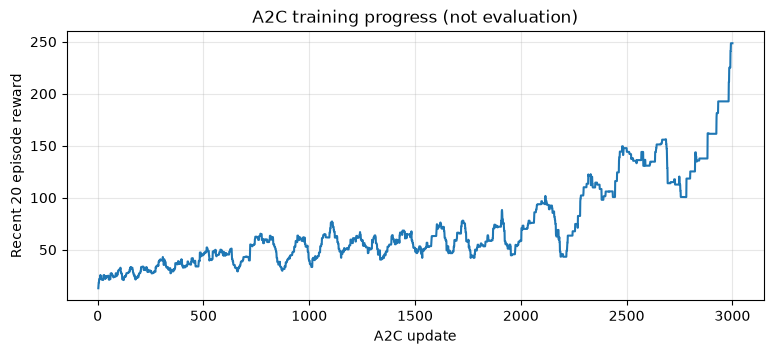

In [21]:
plt.figure(figsize=(9, 3.5))
plt.plot(a2c_hist['update'], a2c_hist['recent20_reward'])
plt.xlabel('A2C update')
plt.ylabel('Recent 20 episode reward')
plt.title('A2C training progress (not evaluation)')
plt.grid(alpha=0.3)
plt.show()

이건 강사님 결과

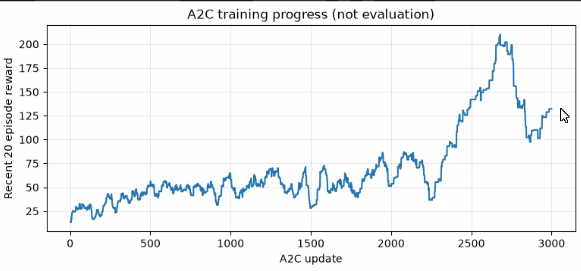